# ЛР №4: Алгоритм Apriori для пошуку асоціативних правил

**Мета:** Реалізувати та застосувати алгоритм APRIORI для розв'язання задачі пошуку асоціативних правил.

**План:**
1. Згенерувати базу даних із 100 транзакцій з 10 предметів
2. Проаналізувати базу та вибрати мінімальний рівень підтримки та достовірності
3. Знайти часті 1-, 2-,... предметні набори
4. Згенерувати асоціативні правила

## Теоретичні відомості

### Алгоритм Apriori

**Apriori** — класичний алгоритм Data Mining для виявлення асоціативних правил у транзакційних базах даних.

#### Основні поняття:

1. **Транзакція** — набір предметів, куплених разом (наприклад, {хліб, молоко, масло})

2. **Підтримка (Support)** — частка транзакцій, що містять набір предметів:
   ```
   support(X) = кількість транзакцій з X / загальна кількість транзакцій
   ```

3. **Достовірність (Confidence)** — ймовірність появи Y за умови появи X:
   ```
   confidence(X → Y) = support(X ∪ Y) / support(X)
   ```

4. **Lift** — показує, наскільки сильніше пов'язані X та Y порівняно з випадковим розподілом:
   ```
   lift(X → Y) = confidence(X → Y) / support(Y)
   ```

#### Властивість анти-монотонності:

Якщо набір X є нечастим, то всі його надмножини також будуть нечастими.

Це дозволяє значно скоротити простір пошуку!

#### Етапи алгоритму:

1. **Генерація кандидатів** — створити кандидати k-предметних наборів
2. **Підрахунок підтримки** — порахувати support для кожного кандидата
3. **Відсіювання** — відкинути набори з support < min_support
4. **Генерація правил** — на основі частих наборів створити асоціативні правила

## Підготовка середовища

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from itertools import combinations, chain
from collections import defaultdict, Counter
import json

# Налаштування
import warnings
warnings.filterwarnings('ignore')

# Шляхи
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Налаштування візуалізації
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Середовище підготовлено!")

Середовище підготовлено!


---
# Крок 1: Генерація бази транзакцій

## 1.1. Визначення предметів та генерація транзакцій

In [2]:
# Налаштування генерації
np.random.seed(42)  # для відтворюваності

# 10 предметів (товарів)
ITEMS = [
    "Хліб",
    "Молоко",
    "Масло",
    "Сир",
    "Яйця",
    "Цукор",
    "Кава",
    "Чай",
    "Печиво",
    "Шоколад"
]

N_TRANSACTIONS = 100  # кількість транзакцій
N_ITEMS = len(ITEMS)

print(f"Предмети ({N_ITEMS}): {', '.join(ITEMS)}")
print(f"\nГенеруємо {N_TRANSACTIONS} транзакцій...")

Предмети (10): Хліб, Молоко, Масло, Сир, Яйця, Цукор, Кава, Чай, Печиво, Шоколад

Генеруємо 100 транзакцій...


In [3]:
def generate_transactions(n_transactions, items, min_items=1, max_items=6):
    """
    Генерує транзакції з реалістичними залежностями між товарами.
    
    Створюємо зв'язані групи товарів:
    - Молочні: Молоко, Масло, Сир
    - Сніданок: Хліб, Масло, Яйця
    - Напої: Кава, Чай, Цукор
    - Солодощі: Печиво, Шоколад, Чай
    """
    transactions = []
    
    # Визначаємо зв'язані групи товарів
    groups = [
        ["Молоко", "Масло", "Сир"],           # Молочні продукти
        ["Хліб", "Масло", "Яйця"],            # Сніданок
        ["Кава", "Чай", "Цукор"],             # Напої
        ["Печиво", "Шоколад", "Чай"],         # Солодощі
        ["Хліб", "Молоко"]                    # Базові продукти
    ]
    
    for _ in range(n_transactions):
        transaction = set()
        
        # 70% транзакцій включають зв'язані групи
        if np.random.random() < 0.7:
            # Вибираємо 1-2 групи
            n_groups = np.random.randint(1, 3)
            selected_groups = np.random.choice(len(groups), n_groups, replace=False)
            
            for group_idx in selected_groups:
                group = groups[group_idx]
                # Беремо 50-100% товарів з групи
                n_from_group = np.random.randint(max(1, len(group)//2), len(group) + 1)
                transaction.update(np.random.choice(group, n_from_group, replace=False))
        
        # Додаємо випадкові товари
        current_size = len(transaction)
        target_size = np.random.randint(min_items, max_items + 1)
        
        if current_size < target_size:
            remaining_items = [item for item in items if item not in transaction]
            if remaining_items:
                n_additional = min(target_size - current_size, len(remaining_items))
                transaction.update(np.random.choice(remaining_items, n_additional, replace=False))
        
        transactions.append(sorted(list(transaction)))
    
    return transactions

# Генеруємо транзакції
transactions = generate_transactions(N_TRANSACTIONS, ITEMS)

print(f"Згенеровано {len(transactions)} транзакцій")
print(f"\nПриклади транзакцій:")
for i, trans in enumerate(transactions[:5], 1):
    print(f"  T{i}: {trans}")

Згенеровано 100 транзакцій

Приклади транзакцій:
  T1: [np.str_('Масло'), np.str_('Хліб'), np.str_('Яйця')]
  T2: [np.str_('Молоко'), np.str_('Печиво'), np.str_('Сир'), np.str_('Шоколад')]
  T3: [np.str_('Кава'), np.str_('Масло'), np.str_('Молоко'), np.str_('Сир'), np.str_('Хліб'), np.str_('Шоколад')]
  T4: [np.str_('Масло'), np.str_('Цукор'), np.str_('Чай'), np.str_('Шоколад'), np.str_('Яйця')]
  T5: [np.str_('Масло'), np.str_('Молоко'), np.str_('Сир')]


## 1.2. Збереження транзакцій у файл

In [4]:
# Зберігаємо у форматі JSON
transactions_file = DATA_DIR / "transactions.json"
with open(transactions_file, 'w', encoding='utf-8') as f:
    json.dump(transactions, f, ensure_ascii=False, indent=2)

# Зберігаємо у форматі CSV
transactions_df = pd.DataFrame([
    {'transaction_id': i+1, 'items': ', '.join(trans)}
    for i, trans in enumerate(transactions)
])
transactions_df.to_csv(DATA_DIR / "transactions.csv", index=False, encoding='utf-8-sig')

print(f"✓ Транзакції збережено:")
print(f"  - {transactions_file}")
print(f"  - {DATA_DIR / 'transactions.csv'}")

✓ Транзакції збережено:
  - data\transactions.json
  - data\transactions.csv


## 1.3. Аналіз бази транзакцій

In [5]:
# Базова статистика
transaction_sizes = [len(t) for t in transactions]

print("Статистика бази транзакцій:")
print("="*60)
print(f"Загальна кількість транзакцій: {len(transactions)}")
print(f"Загальна кількість унікальних предметів: {len(ITEMS)}")
print(f"\nРозмір транзакцій:")
print(f"  Мінімум: {min(transaction_sizes)} предметів")
print(f"  Максимум: {max(transaction_sizes)} предметів")
print(f"  Середнє: {np.mean(transaction_sizes):.2f} предметів")
print(f"  Медіана: {np.median(transaction_sizes):.1f} предметів")

# Частота кожного предмета
item_counts = Counter()
for trans in transactions:
    item_counts.update(trans)

print(f"\nЧастота появи предметів:")
for item, count in item_counts.most_common():
    support = count / len(transactions)
    print(f"  {item:12s}: {count:3d} транзакцій ({support:6.1%} підтримка)")

Статистика бази транзакцій:
Загальна кількість транзакцій: 100
Загальна кількість унікальних предметів: 10

Розмір транзакцій:
  Мінімум: 1 предметів
  Максимум: 6 предметів
  Середнє: 3.66 предметів
  Медіана: 4.0 предметів

Частота появи предметів:
  Масло       :  53 транзакцій ( 53.0% підтримка)
  Хліб        :  44 транзакцій ( 44.0% підтримка)
  Молоко      :  43 транзакцій ( 43.0% підтримка)
  Чай         :  41 транзакцій ( 41.0% підтримка)
  Шоколад     :  34 транзакцій ( 34.0% підтримка)
  Сир         :  33 транзакцій ( 33.0% підтримка)
  Яйця        :  31 транзакцій ( 31.0% підтримка)
  Цукор       :  31 транзакцій ( 31.0% підтримка)
  Печиво      :  28 транзакцій ( 28.0% підтримка)
  Кава        :  28 транзакцій ( 28.0% підтримка)


## 1.4. Візуалізація бази транзакцій

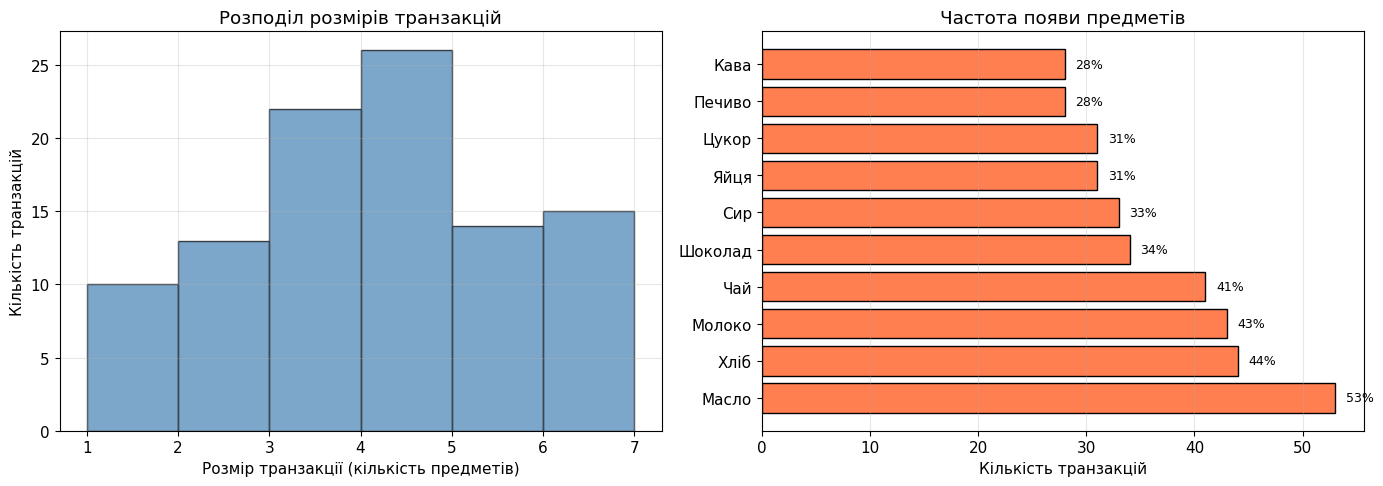

✓ Візуалізацію збережено: figures/transactions_analysis.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Розподіл розмірів транзакцій
ax1 = axes[0]
ax1.hist(transaction_sizes, bins=range(1, max(transaction_sizes)+2), 
         edgecolor='black', alpha=0.7, color='steelblue')
ax1.set_xlabel('Розмір транзакції (кількість предметів)')
ax1.set_ylabel('Кількість транзакцій')
ax1.set_title('Розподіл розмірів транзакцій')
ax1.grid(True, alpha=0.3)

# Частота предметів
ax2 = axes[1]
items_sorted = [item for item, _ in item_counts.most_common()]
counts_sorted = [count for _, count in item_counts.most_common()]
bars = ax2.barh(items_sorted, counts_sorted, color='coral', edgecolor='black')
ax2.set_xlabel('Кількість транзакцій')
ax2.set_title('Частота появи предметів')
ax2.grid(True, alpha=0.3, axis='x')

# Додаємо підписи підтримки
for i, (bar, count) in enumerate(zip(bars, counts_sorted)):
    support = count / len(transactions)
    ax2.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
             f'{support:.0%}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "transactions_analysis.png", dpi=120, bbox_inches='tight')
plt.show()

print("✓ Візуалізацію збережено: figures/transactions_analysis.png")

---
# Крок 2: Вибір параметрів min_support та min_confidence

In [7]:
# Аналізуємо розподіл підтримки
supports = sorted([count / len(transactions) for count in item_counts.values()], reverse=True)

print("Аналіз підтримки одиничних предметів:")
print("="*60)
print(f"Максимальна підтримка: {max(supports):.1%}")
print(f"Мінімальна підтримка:  {min(supports):.1%}")
print(f"Медіанна підтримка:    {np.median(supports):.1%}")

# Вибираємо параметри
MIN_SUPPORT = 0.15      # 15% - достатньо низько, щоб знайти цікаві патерни
MIN_CONFIDENCE = 0.6    # 60% - високий рівень достовірності

print(f"\n✓ Обрані параметри:")
print(f"  min_support    = {MIN_SUPPORT:.1%} ({int(MIN_SUPPORT * len(transactions))} транзакцій)")
print(f"  min_confidence = {MIN_CONFIDENCE:.1%}")

print(f"\nОбґрунтування:")
print(f"  - min_support = {MIN_SUPPORT:.1%} дозволить знайти предмети, що зустрічаються")
print(f"    хоча б у {int(MIN_SUPPORT * len(transactions))} транзакціях (достатньо рідкісні, але значущі)")
print(f"  - min_confidence = {MIN_CONFIDENCE:.1%} забезпечить високу достовірність правил")
print(f"    (якщо купується X, то Y купується в {MIN_CONFIDENCE:.0%}+ випадків)")

Аналіз підтримки одиничних предметів:
Максимальна підтримка: 53.0%
Мінімальна підтримка:  28.0%
Медіанна підтримка:    33.5%

✓ Обрані параметри:
  min_support    = 15.0% (15 транзакцій)
  min_confidence = 60.0%

Обґрунтування:
  - min_support = 15.0% дозволить знайти предмети, що зустрічаються
    хоча б у 15 транзакціях (достатньо рідкісні, але значущі)
  - min_confidence = 60.0% забезпечить високу достовірність правил
    (якщо купується X, то Y купується в 60%+ випадків)


---
# Крок 3: Реалізація алгоритму Apriori

## 3.1. Допоміжні функції

In [8]:
def calculate_support(itemset, transactions):
    """Обчислює підтримку для набору предметів."""
    itemset = frozenset(itemset)
    count = sum(1 for trans in transactions if itemset.issubset(trans))
    return count / len(transactions)

def get_frequent_1_itemsets(transactions, min_support):
    """Знаходить часті 1-предметні набори."""
    item_counts = Counter()
    for trans in transactions:
        item_counts.update(trans)
    
    n_transactions = len(transactions)
    frequent_items = {}
    
    for item, count in item_counts.items():
        support = count / n_transactions
        if support >= min_support:
            frequent_items[frozenset([item])] = support
    
    return frequent_items

def generate_candidates(prev_frequent, k):
    """Генерує кандидати k-предметних наборів з (k-1)-предметних."""
    candidates = set()
    items_list = list(prev_frequent.keys())
    
    for i in range(len(items_list)):
        for j in range(i + 1, len(items_list)):
            # Об'єднуємо два (k-1)-набори
            union = items_list[i] | items_list[j]
            
            # Якщо розмір об'єднання = k, це кандидат
            if len(union) == k:
                # Перевіряємо, чи всі (k-1)-підмножини є частими (pruning)
                subsets_frequent = True
                for item in union:
                    subset = union - frozenset([item])
                    if subset not in prev_frequent:
                        subsets_frequent = False
                        break
                
                if subsets_frequent:
                    candidates.add(union)
    
    return candidates

print("✓ Допоміжні функції визначено")

✓ Допоміжні функції визначено


## 3.2. Основний алгоритм Apriori

In [9]:
def apriori(transactions, min_support):
    """
    Алгоритм Apriori для пошуку частих наборів предметів.
    
    Повертає словник: {k: {itemset: support}} для кожного k.
    """
    print(f"\nЗапуск алгоритму Apriori (min_support={min_support:.1%})...")
    print("="*70)
    
    # Конвертуємо транзакції у frozenset для швидкої перевірки
    trans_sets = [frozenset(trans) for trans in transactions]
    
    all_frequent = {}  # {k: {itemset: support}}
    
    # Крок 1: Знаходимо часті 1-предметні набори
    frequent_k = get_frequent_1_itemsets(transactions, min_support)
    k = 1
    
    print(f"Ітерація {k}: знайдено {len(frequent_k)} частих {k}-предметних наборів")
    all_frequent[k] = frequent_k
    
    # Крок 2-N: Ітеративно знаходимо k-предметні набори
    while frequent_k:
        k += 1
        
        # Генеруємо кандидати
        candidates = generate_candidates(frequent_k, k)
        
        if not candidates:
            break
        
        # Підраховуємо підтримку кандидатів
        candidate_support = {}
        for candidate in candidates:
            count = sum(1 for trans in trans_sets if candidate.issubset(trans))
            support = count / len(transactions)
            
            if support >= min_support:
                candidate_support[candidate] = support
        
        if candidate_support:
            print(f"Ітерація {k}: знайдено {len(candidate_support)} частих {k}-предметних наборів")
            all_frequent[k] = candidate_support
            frequent_k = candidate_support
        else:
            print(f"Ітерація {k}: частих наборів не знайдено. Зупинка.")
            break
    
    print("="*70)
    total_frequent = sum(len(items) for items in all_frequent.values())
    print(f"✓ Алгоритм завершено. Знайдено {total_frequent} частих наборів")
    
    return all_frequent

print("✓ Функція Apriori визначена")

✓ Функція Apriori визначена


## 3.3. Запуск алгоритму Apriori

In [10]:
# Запускаємо Apriori
frequent_itemsets = apriori(transactions, MIN_SUPPORT)


Запуск алгоритму Apriori (min_support=15.0%)...
Ітерація 1: знайдено 10 частих 1-предметних наборів
Ітерація 2: знайдено 16 частих 2-предметних наборів
Ітерація 3: частих наборів не знайдено. Зупинка.
✓ Алгоритм завершено. Знайдено 26 частих наборів


## 3.4. Відображення частих наборів

In [11]:
print("\n" + "="*70)
print("ЧАСТІ НАБОРИ ПРЕДМЕТІВ")
print("="*70)

for k in sorted(frequent_itemsets.keys()):
    itemsets = frequent_itemsets[k]
    print(f"\n{k}-предметні набори ({len(itemsets)} наборів):")
    print("-" * 70)
    
    # Сортуємо за підтримкою (від більшої до меншої)
    sorted_itemsets = sorted(itemsets.items(), key=lambda x: x[1], reverse=True)
    
    for itemset, support in sorted_itemsets:
        items_str = "{" + ", ".join(sorted(itemset)) + "}"
        print(f"  {items_str:40s} → support = {support:6.1%} ({int(support * len(transactions))} транзакцій)")

# Зберігаємо результати
frequent_file = DATA_DIR / "frequent_itemsets.json"
frequent_data = {
    str(k): {
        str(sorted(list(itemset))): support 
        for itemset, support in items.items()
    }
    for k, items in frequent_itemsets.items()
}

with open(frequent_file, 'w', encoding='utf-8') as f:
    json.dump(frequent_data, f, ensure_ascii=False, indent=2)

print(f"\n✓ Часті набори збережено: {frequent_file}")


ЧАСТІ НАБОРИ ПРЕДМЕТІВ

1-предметні набори (10 наборів):
----------------------------------------------------------------------
  {Масло}                                  → support =  53.0% (53 транзакцій)
  {Хліб}                                   → support =  44.0% (44 транзакцій)
  {Молоко}                                 → support =  43.0% (43 транзакцій)
  {Чай}                                    → support =  41.0% (41 транзакцій)
  {Шоколад}                                → support =  34.0% (34 транзакцій)
  {Сир}                                    → support =  33.0% (33 транзакцій)
  {Яйця}                                   → support =  31.0% (31 транзакцій)
  {Цукор}                                  → support =  31.0% (31 транзакцій)
  {Печиво}                                 → support =  28.0% (28 транзакцій)
  {Кава}                                   → support =  28.0% (28 транзакцій)

2-предметні набори (16 наборів):
---------------------------------------------------------

---
# Крок 4: Генерація асоціативних правил

## 4.1. Функція генерації правил

In [12]:
def generate_rules(frequent_itemsets, min_confidence):
    """
    Генерує асоціативні правила з частих наборів.
    
    Для кожного частого набору розмірності >= 2:
    - Генерує всі можливі правила X → Y
    - Перевіряє достовірність
    - Обчислює lift
    
    Повертає список правил: [(antecedent, consequent, support, confidence, lift)]
    """
    rules = []
    
    # Створюємо словник всіх частих наборів для швидкого доступу
    all_itemsets_support = {}
    for k_itemsets in frequent_itemsets.values():
        all_itemsets_support.update(k_itemsets)
    
    # Генеруємо правила з наборів розміру >= 2
    for k in range(2, max(frequent_itemsets.keys()) + 1):
        if k not in frequent_itemsets:
            continue
        
        for itemset, itemset_support in frequent_itemsets[k].items():
            # Для кожного непорожнього підмножини (antecedent)
            items = list(itemset)
            
            # Перебираємо всі можливі розбиття на antecedent → consequent
            for i in range(1, len(items)):
                for antecedent_tuple in combinations(items, i):
                    antecedent = frozenset(antecedent_tuple)
                    consequent = itemset - antecedent
                    
                    # Перевіряємо, чи antecedent є частим набором
                    if antecedent not in all_itemsets_support:
                        continue
                    
                    antecedent_support = all_itemsets_support[antecedent]
                    
                    # Обчислюємо достовірність: confidence(X → Y) = support(X ∪ Y) / support(X)
                    confidence = itemset_support / antecedent_support
                    
                    if confidence >= min_confidence:
                        # Обчислюємо lift
                        consequent_support = all_itemsets_support.get(consequent, 0)
                        lift = confidence / consequent_support if consequent_support > 0 else 0
                        
                        rules.append({
                            'antecedent': antecedent,
                            'consequent': consequent,
                            'support': itemset_support,
                            'confidence': confidence,
                            'lift': lift
                        })
    
    return rules

print("✓ Функція генерації правил визначена")

✓ Функція генерації правил визначена


## 4.2. Генерація та відображення правил

In [13]:
# Генеруємо правила
print(f"\nГенерація асоціативних правил (min_confidence={MIN_CONFIDENCE:.1%})...")
rules = generate_rules(frequent_itemsets, MIN_CONFIDENCE)

# Сортуємо за lift (від більшого до меншого)
rules_sorted = sorted(rules, key=lambda x: x['lift'], reverse=True)

print(f"✓ Знайдено {len(rules_sorted)} асоціативних правил\n")

print("="*90)
print("АСОЦІАТИВНІ ПРАВИЛА")
print("="*90)
print(f"{'Правило':<50s} {'Support':>10s} {'Conf':>8s} {'Lift':>8s}")
print("-"*90)

for rule in rules_sorted:
    antecedent_str = "{" + ", ".join(sorted(rule['antecedent'])) + "}"
    consequent_str = "{" + ", ".join(sorted(rule['consequent'])) + "}"
    rule_str = f"{antecedent_str} → {consequent_str}"
    
    print(f"{rule_str:<50s} {rule['support']:>9.1%} {rule['confidence']:>7.1%} {rule['lift']:>8.2f}")

print("="*90)


Генерація асоціативних правил (min_confidence=60.0%)...
✓ Знайдено 4 асоціативних правил

АСОЦІАТИВНІ ПРАВИЛА
Правило                                               Support     Conf     Lift
------------------------------------------------------------------------------------------
{Кава} → {Цукор}                                       17.0%   60.7%     1.96
{Сир} → {Масло}                                        24.0%   72.7%     1.37
{Яйця} → {Масло}                                       21.0%   67.7%     1.28
{Молоко} → {Масло}                                     26.0%   60.5%     1.14


## 4.3. Інтерпретація правил

In [14]:
print("\nІНТЕРПРЕТАЦІЯ ТОП-5 ПРАВИЛ:")
print("="*90)

for i, rule in enumerate(rules_sorted[:5], 1):
    antecedent_str = ", ".join(sorted(rule['antecedent']))
    consequent_str = ", ".join(sorted(rule['consequent']))
    
    print(f"\n{i}. {antecedent_str} → {consequent_str}")
    print(f"   Support:    {rule['support']:.1%} - ця комбінація з'являється у {rule['support']:.1%} транзакцій")
    print(f"   Confidence: {rule['confidence']:.1%} - якщо купується [{antecedent_str}],")
    print(f"               то у {rule['confidence']:.1%} випадків купується і [{consequent_str}]")
    print(f"   Lift:       {rule['lift']:.2f} - ці товари купуються разом у {rule['lift']:.2f} разів частіше,")
    print(f"               ніж якби вони були незалежні")
    
    if rule['lift'] > 1:
        print(f"   ⇒ Сильний позитивний зв'язок! Рекомендується розміщувати поряд.")
    elif rule['lift'] < 1:
        print(f"   ⇒ Негативний зв'язок. Покупці рідко купують це разом.")
    else:
        print(f"   ⇒ Товари незалежні.")


ІНТЕРПРЕТАЦІЯ ТОП-5 ПРАВИЛ:

1. Кава → Цукор
   Support:    17.0% - ця комбінація з'являється у 17.0% транзакцій
   Confidence: 60.7% - якщо купується [Кава],
               то у 60.7% випадків купується і [Цукор]
   Lift:       1.96 - ці товари купуються разом у 1.96 разів частіше,
               ніж якби вони були незалежні
   ⇒ Сильний позитивний зв'язок! Рекомендується розміщувати поряд.

2. Сир → Масло
   Support:    24.0% - ця комбінація з'являється у 24.0% транзакцій
   Confidence: 72.7% - якщо купується [Сир],
               то у 72.7% випадків купується і [Масло]
   Lift:       1.37 - ці товари купуються разом у 1.37 разів частіше,
               ніж якби вони були незалежні
   ⇒ Сильний позитивний зв'язок! Рекомендується розміщувати поряд.

3. Яйця → Масло
   Support:    21.0% - ця комбінація з'являється у 21.0% транзакцій
   Confidence: 67.7% - якщо купується [Яйця],
               то у 67.7% випадків купується і [Масло]
   Lift:       1.28 - ці товари купуються разом у 1.2

## 4.4. Збереження правил

In [15]:
# Зберігаємо правила у CSV
rules_df = pd.DataFrame([
    {
        'antecedent': ', '.join(sorted(r['antecedent'])),
        'consequent': ', '.join(sorted(r['consequent'])),
        'support': r['support'],
        'confidence': r['confidence'],
        'lift': r['lift']
    }
    for r in rules_sorted
])

rules_df.to_csv(DATA_DIR / "association_rules.csv", index=False, encoding='utf-8-sig')
print(f"\n✓ Правила збережено: {DATA_DIR / 'association_rules.csv'}")


✓ Правила збережено: data\association_rules.csv


---
# Крок 5: Візуалізація результатів

## 5.1. Візуалізація частих наборів

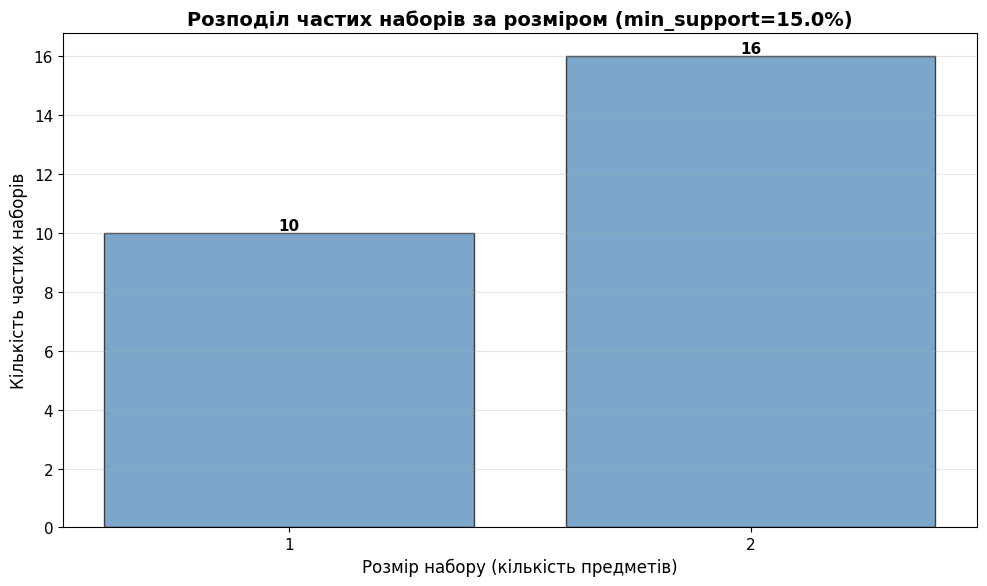

✓ Графік збережено: figures/frequent_itemsets_distribution.png


In [16]:
# Підрахунок кількості наборів за розміром
itemset_counts = {k: len(items) for k, items in frequent_itemsets.items()}

fig, ax = plt.subplots(figsize=(10, 6))
sizes = list(itemset_counts.keys())
counts = list(itemset_counts.values())

bars = ax.bar(sizes, counts, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Розмір набору (кількість предметів)', fontsize=12)
ax.set_ylabel('Кількість частих наборів', fontsize=12)
ax.set_title(f'Розподіл частих наборів за розміром (min_support={MIN_SUPPORT:.1%})', fontsize=14, fontweight='bold')
ax.set_xticks(sizes)
ax.grid(True, alpha=0.3, axis='y')

# Додаємо підписи
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(count)}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / "frequent_itemsets_distribution.png", dpi=120, bbox_inches='tight')
plt.show()

print("✓ Графік збережено: figures/frequent_itemsets_distribution.png")

## 5.2. Візуалізація асоціативних правил

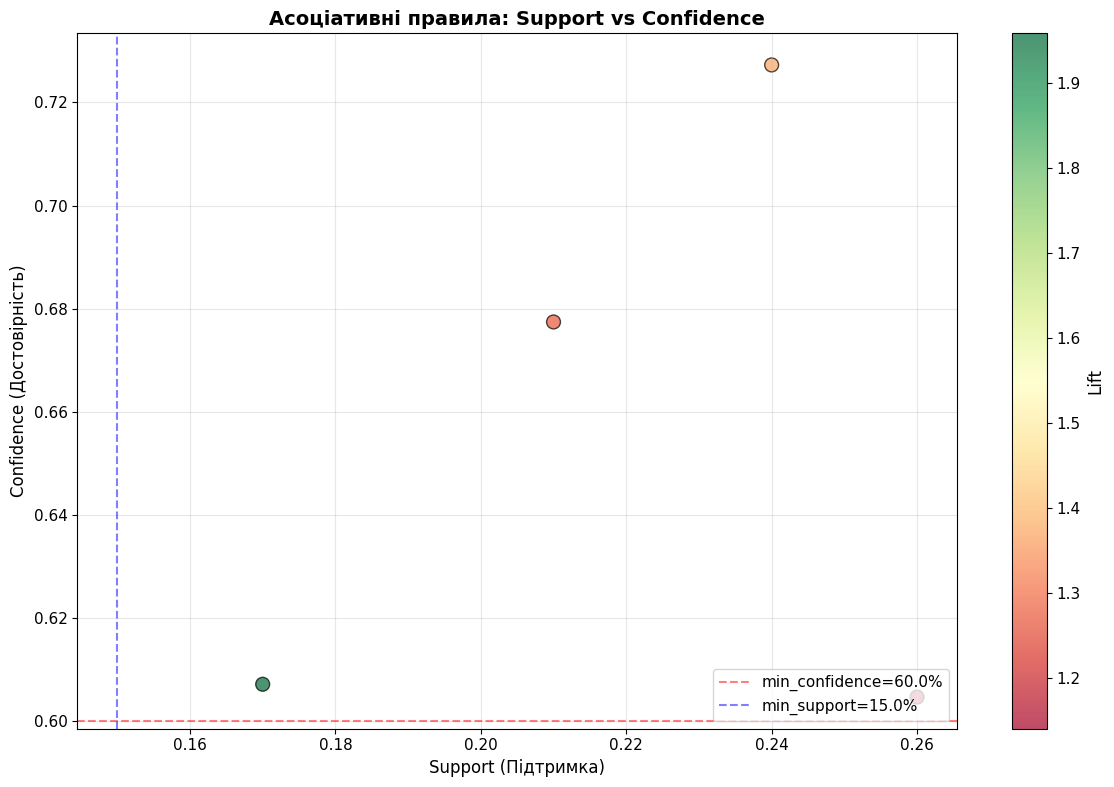

✓ Графік збережено: figures/rules_support_vs_confidence.png


In [17]:
# Scatter plot: Support vs Confidence з кольором за Lift
fig, ax = plt.subplots(figsize=(12, 8))

supports = [r['support'] for r in rules_sorted]
confidences = [r['confidence'] for r in rules_sorted]
lifts = [r['lift'] for r in rules_sorted]

scatter = ax.scatter(supports, confidences, c=lifts, s=100, 
                     cmap='RdYlGn', edgecolor='black', alpha=0.7)
ax.set_xlabel('Support (Підтримка)', fontsize=12)
ax.set_ylabel('Confidence (Достовірність)', fontsize=12)
ax.set_title('Асоціативні правила: Support vs Confidence', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

# Colorbar для Lift
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Lift', fontsize=12)

# Додаємо лінії порогів
ax.axhline(MIN_CONFIDENCE, color='red', linestyle='--', alpha=0.5, label=f'min_confidence={MIN_CONFIDENCE:.1%}')
ax.axvline(MIN_SUPPORT, color='blue', linestyle='--', alpha=0.5, label=f'min_support={MIN_SUPPORT:.1%}')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(FIG_DIR / "rules_support_vs_confidence.png", dpi=120, bbox_inches='tight')
plt.show()

print("✓ Графік збережено: figures/rules_support_vs_confidence.png")

## 5.3. Топ-10 правил за Lift

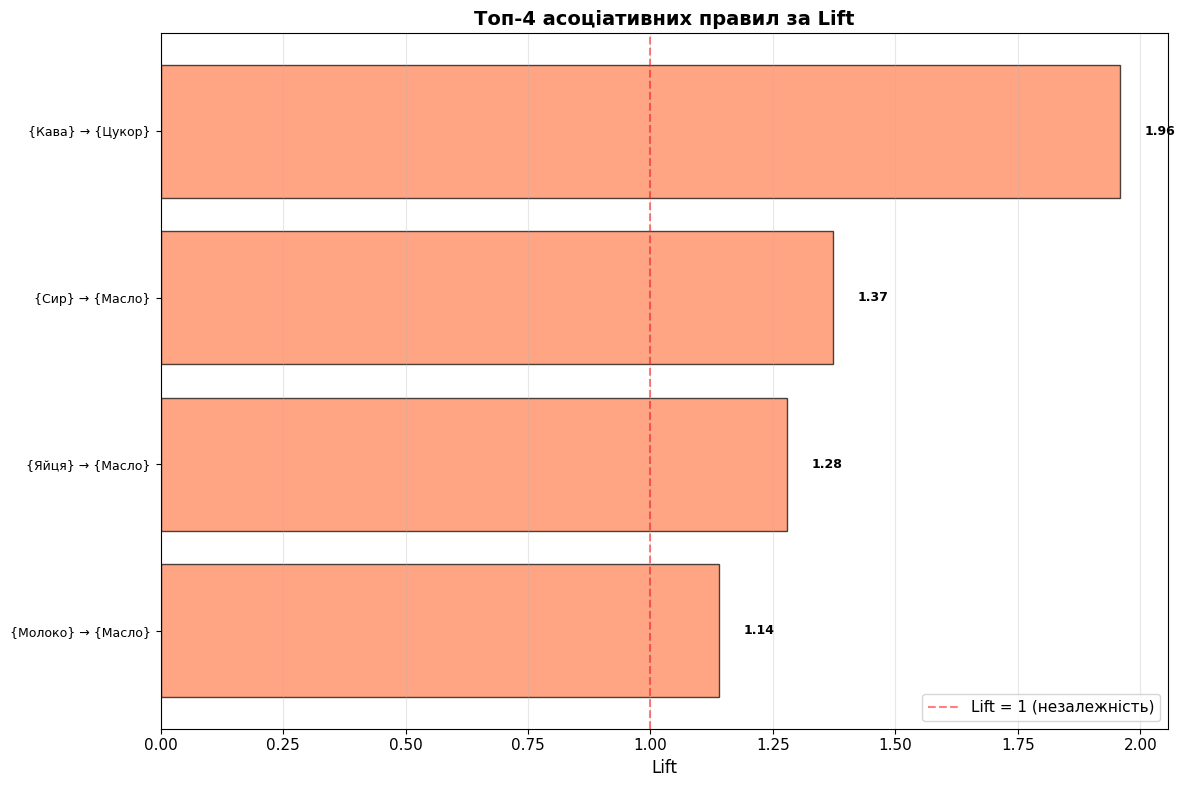

✓ Графік збережено: figures/top_rules_by_lift.png


In [18]:
# Візуалізуємо топ-10 правил
top_n = min(10, len(rules_sorted))
top_rules = rules_sorted[:top_n]

fig, ax = plt.subplots(figsize=(12, 8))

rule_labels = [
    f"{{{', '.join(sorted(r['antecedent']))}}} → {{{', '.join(sorted(r['consequent']))}}}"
    for r in top_rules
]
lifts_top = [r['lift'] for r in top_rules]

y_pos = np.arange(len(rule_labels))
bars = ax.barh(y_pos, lifts_top, color='coral', edgecolor='black', alpha=0.7)

ax.set_yticks(y_pos)
ax.set_yticklabels(rule_labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Lift', fontsize=12)
ax.set_title(f'Топ-{top_n} асоціативних правил за Lift', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

# Додаємо вертикальну лінію lift=1
ax.axvline(1, color='red', linestyle='--', alpha=0.5, label='Lift = 1 (незалежність)')
ax.legend()

# Додаємо підписи значень
for bar, lift in zip(bars, lifts_top):
    width = bar.get_width()
    ax.text(width + 0.05, bar.get_y() + bar.get_height()/2,
            f'{lift:.2f}', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / "top_rules_by_lift.png", dpi=120, bbox_inches='tight')
plt.show()

print("✓ Графік збережено: figures/top_rules_by_lift.png")

---
# Висновки

In [19]:
print("\n" + "="*90)
print("ПІДСУМКИ ЛАБОРАТОРНОЇ РОБОТИ №4")
print("="*90)

print(f"\n1. БАЗА ТРАНЗАКЦІЙ:")
print(f"   - Згенеровано {len(transactions)} транзакцій")
print(f"   - Кількість унікальних предметів: {len(ITEMS)}")
print(f"   - Середній розмір транзакції: {np.mean(transaction_sizes):.2f} предметів")

print(f"\n2. ПАРАМЕТРИ АЛГОРИТМУ:")
print(f"   - min_support = {MIN_SUPPORT:.1%}")
print(f"   - min_confidence = {MIN_CONFIDENCE:.1%}")

print(f"\n3. ЧАСТІ НАБОРИ:")
total_frequent = sum(len(items) for items in frequent_itemsets.values())
print(f"   - Всього знайдено {total_frequent} частих наборів")
for k, items in sorted(frequent_itemsets.items()):
    print(f"   - {k}-предметних наборів: {len(items)}")

print(f"\n4. АСОЦІАТИВНІ ПРАВИЛА:")
print(f"   - Всього знайдено {len(rules_sorted)} правил")
print(f"   - Середній lift: {np.mean([r['lift'] for r in rules_sorted]):.2f}")
print(f"   - Максимальний lift: {max([r['lift'] for r in rules_sorted]):.2f}")

print(f"\n5. КЛЮЧОВІ ІНСАЙТИ:")
if rules_sorted:
    best_rule = rules_sorted[0]
    ant_str = ", ".join(sorted(best_rule['antecedent']))
    cons_str = ", ".join(sorted(best_rule['consequent']))
    print(f"   - Найсильніше правило: {{{ant_str}}} → {{{cons_str}}}")
    print(f"     (lift={best_rule['lift']:.2f}, confidence={best_rule['confidence']:.1%})")
    print(f"   - Це означає, що покупці, які купують {ant_str},")
    print(f"     купують також {cons_str} у {best_rule['confidence']:.1%} випадків")

print(f"\n6. ФАЙЛИ РЕЗУЛЬТАТІВ:")
print(f"   - data/transactions.json - база транзакцій")
print(f"   - data/transactions.csv - база транзакцій (CSV)")
print(f"   - data/frequent_itemsets.json - часті набори")
print(f"   - data/association_rules.csv - асоціативні правила")
print(f"   - figures/*.png - візуалізації")

print("\n" + "="*90)
print("✓ ЛАБОРАТОРНА РОБОТА ВИКОНАНА УСПІШНО!")
print("="*90)


ПІДСУМКИ ЛАБОРАТОРНОЇ РОБОТИ №4

1. БАЗА ТРАНЗАКЦІЙ:
   - Згенеровано 100 транзакцій
   - Кількість унікальних предметів: 10
   - Середній розмір транзакції: 3.66 предметів

2. ПАРАМЕТРИ АЛГОРИТМУ:
   - min_support = 15.0%
   - min_confidence = 60.0%

3. ЧАСТІ НАБОРИ:
   - Всього знайдено 26 частих наборів
   - 1-предметних наборів: 10
   - 2-предметних наборів: 16

4. АСОЦІАТИВНІ ПРАВИЛА:
   - Всього знайдено 4 правил
   - Середній lift: 1.44
   - Максимальний lift: 1.96

5. КЛЮЧОВІ ІНСАЙТИ:
   - Найсильніше правило: {Кава} → {Цукор}
     (lift=1.96, confidence=60.7%)
   - Це означає, що покупці, які купують Кава,
     купують також Цукор у 60.7% випадків

6. ФАЙЛИ РЕЗУЛЬТАТІВ:
   - data/transactions.json - база транзакцій
   - data/transactions.csv - база транзакцій (CSV)
   - data/frequent_itemsets.json - часті набори
   - data/association_rules.csv - асоціативні правила
   - figures/*.png - візуалізації

✓ ЛАБОРАТОРНА РОБОТА ВИКОНАНА УСПІШНО!
